# SRN chunking

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mbontrid/SRN-statistical-learning-experimentation/blob/main/notebooks/srn_chunking.ipynb)

In [1]:
import os
import sys
from collections.abc import Callable, Sequence
from pathlib import Path
from random import choice

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from itertools import combinations_with_replacement, combinations
import torch
from IPython.display import display


In [2]:
STATIC_BUILD = os.getenv("STATIC_BUILD") == "1"

# Dynamically handle path addition for both local and Colab environments
current_dir = Path().resolve()
repo_name = 'SRN-statistical-learning-experimentation'

if (current_dir / repo_name).is_dir():
    sys.path.append(str(current_dir / repo_name))
elif (current_dir.parent / repo_name).is_dir():
    sys.path.append(str(current_dir.parent / repo_name))
else:
  # Download the repo (environment). Useful if executed in google colab.
  !git clone https://github.com/mbontrid/SRN-statistical-learning-experimentation
  sys.path.append(str(Path('/content') / repo_name))
  !cd SRN-statistical-learning-experimentation

# Add the repository root to Python's import path.
repo_root = current_dir.parent

if not (repo_root / "src").is_dir():
    repo_root = Path("/content") / repo_name if not STATIC_BUILD else current_dir

if (repo_root / "src").is_dir():
    sys.path.insert(0, str(repo_root))


from src.data.formater import Format, PandasLoader
from src.utils.logger import add_log_level, setup_logger

In [3]:
# global setup parameters

# define the verbose level
#available levels: CRITICAL, ERROR, WARNING, INFO, DEBUG, TRACE
logger_level = "TRACE"

In [4]:
# Logger setup
import logging

if not hasattr(logging, "TRACE"):
	add_log_level("TRACE", 5)

logger = setup_logger(name="logger", level=logger_level)
logger.info("logger set to info level")
logger.trace("TRACE logger activated")



INFO - logger set to info level
TRACE - TRACE logger activated


## Data setup


In [5]:
datasets_path_format = {
    "Result TR 24": (repo_root / "data/input/Results_TR_24.xls", Format.FORMAT_1),
    "Stim Learning S1 L1 (Two positions)": (repo_root / "data/input/stim_Learning_S1.xlsx", Format.FORMAT_2),
    "Stim Learning S1 L2 (Three positions)": (repo_root / "data/input/stim_Learning_S1.xlsx", Format.FORMAT_3),
}

selected_data = next(iter(datasets_path_format))
encoded:np.ndarray|None = None
unique_vals:np.ndarray|None = None


def load_selected_data(selected_data):
    global encoded, unique_vals

    file_path, format_type = datasets_path_format[selected_data]
    loader = PandasLoader(path=file_path, format=format_type)
    responses = loader.get()

    display(f"Selected dataset: {selected_data}")
    display(responses)
    logger.info(f"subjects response per trial:\n{responses}")

    responses = responses.to_numpy().T
    logger.debug(f"responses with array shape (subjects, responses) = {responses}")

    unique_vals, encoded = np.unique(responses.reshape(-1), return_inverse=True)
    encoded = encoded.reshape(responses.shape)

    logger.info(f"unique values = {unique_vals}")
    logger.info(f"number of labels = {len(unique_vals)}")
    logger.debug(f"final encoded shape (subjects, responses) = {encoded.shape}")
    logger.debug(f"encoded values = {encoded}")

if STATIC_BUILD:
    load_selected_data(selected_data)
else:
    data_path_w = widgets.Select(
        options=datasets_path_format.keys(),
        value=selected_data,
        description="File to load:",
        disabled=False,
        style={'description_width': 'initial'}
    )
    display(data_path_w)
    data_path_output = widgets.Output()

    def show_selected_data(_button):
        global selected_data
        selected_data = data_path_w.value
        data_path_output.clear_output()
        with data_path_output:
            load_selected_data(selected_data)

    load_dataset_button = widgets.Button(
        description="Load Dataset",
        button_style="",
        tooltip="Load the dataset and display the subjects responses per trial",
        icon="check",
        style={'description_width': 'initial'}
    )
    load_dataset_button.on_click(show_selected_data)
    show_selected_data(load_dataset_button)
    display(load_dataset_button, data_path_output)

Select(description='File to load:', options=('Result TR 24', 'Stim Learning S1 L1 (Two positions)', 'Stim Lear…

Button(description='Load Dataset', icon='check', style=ButtonStyle(), tooltip='Load the dataset and display th…

Output()

### Stimulus grid
Each stimulus (key, embeding, value) appear as a colored cell on a gridd. This is translated as an array of zeros with only one cell at 1. 

In [39]:
def head_emb_tail_items(
    n_head_tail_pair: int = 3, n_emb: int = 24
) -> tuple[np.ndarray, np.ndarray]:
    """
    Create a dataset with a head, an embedded sequence, and a tail.

    Parameters:
    - n_head_tail: Number of unique values in the head and tail.
    - lenght_heead_tail: Length of the head and tail sequences.
    - n_emb: Number of unique values in the embedded sequence.
    - lenght_emb: Length of the embedded sequence.

    Returns:
    - A numpy array representing the concatenated head, embedded sequence, and tail.
    """

    item_tail_pair = n_head_tail_pair * 2 + n_emb

    items = np.arange(item_tail_pair)
    items = np.random.choice(items, size=item_tail_pair, replace=False)

    head_tail = items[: n_head_tail_pair * 2]
    head_tail = np.reshape(head_tail, (-1, 2))
    emb = items[n_head_tail_pair * 2 :]

    return head_tail, emb




def head_emb_tail_combination(head_tail: np.ndarray, emb: np.ndarray, emb_lenght: int = 1, emb_replacement: bool = False) -> np.ndarray:
    """
    Create a dataset with a head, an embedded sequence, and a tail.

    Parameters:
    - head_tail: A numpy array representing the head and tail sequences.
    - emb: A numpy array representing the embedded sequence.

    Returns:
    - A numpy array representing the concatenated head, embedded sequence, and tail for each sample.
    """

    combins = []
    embedding_combinations = tuple(combinations_with_replacement(emb, emb_lenght) if emb_replacement else combinations(emb, emb_lenght))

    for head, tail in head_tail:
        for embed in embedding_combinations:
            sample = np.concatenate((head.flatten(), embed, tail.flatten()))
            combins.append(sample)

    return np.array(combins)


def make_sequence(head_emb_tail_combins: np.ndarray, seq_lenght: int =1000,) -> np.ndarray:

    tuple_size = head_emb_tail_combins.shape[1]
    tuple_count = seq_lenght // tuple_size
    rng = np.random.default_rng()
    sequence = rng.choice(a=head_emb_tail_combins, size=tuple_count, replace=True)
    sequence = sequence.flatten()

    return sequence


In [40]:

n_head_tail_pair = 3
n_emb = 24
emb_lenght = 1
sequence_lenght = 100

sequence:np.ndarray|None = None


def make_head_emb_tail_sequence(
    n_head_tail_pair: int = 3,
    n_emb: int = 24,
    emb_lenght: int = 1,
    seq_lenght: int = 1000,
) -> np.ndarray:
    head_tail, emb = head_emb_tail_items(n_head_tail_pair=n_head_tail_pair, n_emb=n_emb)
    print(f"Generated head-tail pairs:\n{head_tail}")
    head_emb_tail_combins = head_emb_tail_combination(head_tail, emb, emb_lenght=emb_lenght)
    print(f"Generated sequence tuples:\n{head_emb_tail_combins}")
    
    sequence = make_sequence(head_emb_tail_combins, seq_lenght=seq_lenght)
    print(f"Generated sequence shape: {sequence.shape}")

    return sequence

if STATIC_BUILD:

    sequence = make_head_emb_tail_sequence(
        n_head_tail_pair=n_head_tail_pair,
        n_emb=n_emb,
        emb_lenght=emb_lenght,
        n_samples=sequence_lenght,
    )
else:
    n_head_tail_pair_w = widgets.BoundedIntText(
        value=3,
        min=1,
        max=10000,
        description="Head-Tail Pairs:",
        tooltip="Number of head-tail pairs to generate",
        disabled=False,
        style={'description_width': 'initial'}
    )

    n_embed_w = widgets.BoundedIntText(
        value=n_emb,
        min=0,
        max=10000,
        description="Embeddings:",
        tooltip="Number of embeddings to generate",
        disabled=False,
        style={'description_width': 'initial'}
    )

    embed_lenght_w = widgets.BoundedIntText(
        value=emb_lenght,
        min=0,
        max=100,
        description="Number of embeddings:",
        tooltip="Number of embeddings between head and tail",
        disabled=False,
        style={'description_width': 'initial'}
    )

    sequence_lenght_w = widgets.BoundedIntText(
        value=sequence_lenght,
        min=0,
        max=10000000,
        description="Sequence Length:",
        tooltip="Length of the sequence to generate",
        disabled=False,
        style={'description_width': 'initial'}
    )

    display(n_head_tail_pair_w, n_embed_w, embed_lenght_w, sequence_lenght_w)

    sequence_output = widgets.Output()

    def generate_sequence_action(_button):
        global n_head_tail_pair, n_emb, emb_lenght, sequence_lenght, sequence

        n_head_tail_pair = n_head_tail_pair_w.value
        n_emb = n_embed_w.value
        emb_lenght = embed_lenght_w.value
        sequence_lenght = sequence_lenght_w.value

        sequence_output.clear_output()
        with sequence_output:
            sequence = make_head_emb_tail_sequence(
                n_head_tail_pair=n_head_tail_pair_w.value,
                n_emb=n_embed_w.value,
                emb_lenght=embed_lenght_w.value,
                seq_lenght=sequence_lenght_w.value,
            )
            

    generate_dataset_button = widgets.Button(
        description="Generate sequence",
        button_style="",
        tooltip="Generate the sequence and display the subjects responses per trial",
        icon="check",
        style={'description_width': 'initial'}
    )
    generate_dataset_button.on_click(generate_sequence_action)
    generate_sequence_action(generate_dataset_button)  # Generate the sequence on initial load
    display(generate_dataset_button,sequence_output)


BoundedIntText(value=3, description='Head-Tail Pairs:', max=10000, min=1, style=DescriptionStyle(description_w…

BoundedIntText(value=24, description='Embeddings:', max=10000, style=DescriptionStyle(description_width='initi…

BoundedIntText(value=1, description='Number of embeddings:', style=DescriptionStyle(description_width='initial…

BoundedIntText(value=100, description='Sequence Length:', max=10000000, style=DescriptionStyle(description_wid…

Button(description='Generate sequence', icon='check', style=ButtonStyle(), tooltip='Generate the sequence and …

Output()

In [8]:
def make_stimulus_grid(stimulus: list[int]|int, size:int, grid_max: float=1.0, grid_min: float=0.0) -> torch.Tensor:
    """
    Create a grid with a stimulus at the encoded label position.
    Args:
        stimulus (int): The index of the stimulus to be placed in the grid.
        size (int): The size of the grid.
        grid_max (float): The maximum value for the stimulus.
        grid_min (float): The minimum value for the stimulus.

    Returns:
        torch.Tensor: A tensor representing the grid with the stimulus.
    """
    if not isinstance(stimulus, list):
        stimulus = [stimulus]
        
    grid = torch.ones(size) * grid_min
    for s in stimulus:
        grid[s] = grid_max
        
    return grid

In [9]:
first_head = encoded[0, 0]
first_embed = encoded[0, 1]
first_tail = encoded[0, 2]

logger.info(f"first head={first_head}, first embed={first_embed}, first tail={first_tail}")
logger.info(f"first_head={make_stimulus_grid(stimulus=first_head, size=len(unique_vals), grid_max=1.0, grid_min=0.0)}")
logger.info(f"first_embed={make_stimulus_grid(stimulus=first_embed, size=len(unique_vals), grid_max=1.0, grid_min=0.0)}")
logger.info(f"first_tail={make_stimulus_grid(stimulus=first_tail, size=len(unique_vals), grid_max=1.0, grid_min=0.0)}")

INFO - first head=22, first embed=5, first tail=25
INFO - first_head=tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.])
INFO - first_embed=tensor([0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])
INFO - first_tail=tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])


## SRN implementation

![srn elman diagrma](https://web.stanford.edu/group/pdplab/pdphandbook/srn_net.png)

The SRN is regarded as an early precursor to recurrent neural networks (RNNs).
At each time step, the pattern of activations from the hidden layer is copied to the context units for the next time step.
The context units belong to the input layer and are connected to the hidden units.
The output of the hidden layer is then used to compute the network's output.

![SRN basic architecture](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fwww.researchgate.net%2Fpublication%2F361380872%2Ffigure%2Ffig1%2FAS%3A1169080920875058%401655742020827%2FSchematic-diagram-of-Elman-network-structure-in-simple-recurrent-neural-network.jpg&f=1&nofb=1&ipt=1d5a36f3ef48ba69e88b9f96a9176f2e1ed8232b2019b9d3f7f7335e1ee85f1d)

```mermaid
graph TB;
hidden --> context
input --> hidden
context --> hidden
hidden --> output
```

In [10]:
def make_uniform_tensor(
    extremum: tuple[float, float], shape: Sequence[int], require_grad: bool
):
    """
    Create a tensor with values uniformly distributed between the given extrema.
    Args:
        extremum (tuple[float, float]): The lower and upper bounds of the uniform distribution.
        shape (Sequence[int]): The shape of the tensor to be created.
        grad (bool): Whether to require gradients for the tensor.

    Returns:
        torch.Tensor: A tensor with values uniformly distributed between the given extrema.
    """
    t = torch.empty(*shape)
    t.uniform_(*extremum)
    if require_grad:
        t.requires_grad_()
    return t



In [11]:
class SRN_subject:
    """Basic Elman SRN. Made of two weighted layer, the first one has it's ouptut copied for future concatenation with the next input.

    Attributes:
        lr: learning rate.
        activation: List of activation functions. The function are nessary.
        loss_fn: loss function to use for backpropagation.
        Wxh: Weights of the first layer.
        Why: Weights of the second layer.
        context: After each forward pass, hidden layer is copied in context.
    """

    def __init__(
        self,
        input_size: int,
        hidden_size: int,
        output_size: int,
        activation: tuple[Callable, Callable] = (torch.nn.Tanh(), torch.nn.Sigmoid()),
        lr: float = 0.05,
        momentum: float = 0.9,
        initial_w_unif: tuple[float, float] = (-0.1, 0.1),
        loss_fn: Callable = torch.nn.MSELoss(),
    ):
        self.lr = lr
        self.momentum = momentum
        self.activation = activation
        self.loss_fn = loss_fn

        self.Wxh = make_uniform_tensor(
            extremum=initial_w_unif,
            shape=[hidden_size, input_size + hidden_size],
            require_grad=True,
        )

        self.Why = make_uniform_tensor(
            extremum=initial_w_unif,
            shape=[output_size, hidden_size],
            require_grad=True
        )

        self.bh = torch.zeros(hidden_size, requires_grad=True)
        self.by = torch.zeros(output_size, requires_grad=True)

        self.context = torch.zeros(hidden_size)

    def forward(self, x: torch.Tensor, y: torch.Tensor | None = None):
        # input of hidden layer: input concatenated with previous output of the hidden layer
        x_cat_context = torch.cat([x, self.context], dim=0)
        logger.trace(f"forward pass: x_cat_context={x_cat_context}")


        h: torch.Tensor = self.activation[0](self.Wxh @ x_cat_context + self.bh)
        self.context = h.clone().detach()  # detach the context from the computational graph to prevent backprop through time
        self.context *= self.momentum
        y = self.activation[1](self.Why @ h + self.by)
        return y

    def backprop(self, y_pred, y):

        loss = self.loss_fn(y_pred, y)
        loss.backward()  # compute gradients

        with torch.no_grad():
            self.Wxh -= self.lr * self.Wxh.grad
            self.Why -= self.lr * self.Why.grad
            self.bh -= self.lr * self.bh.grad
            self.by -= self.lr * self.by.grad

            # reset the gradients.
            self.Wxh.grad.zero_()
            self.Why.grad.zero_()
            self.bh.grad.zero_()
            self.by.grad.zero_()

        return loss



Creation of a basic neural network to compare with the SRN.

In [12]:
class NN_subject:
    """Basic feedforward neural network. Made of two weighted layer, the first one has it's ouptut copied for future concatenation with the next input.

    Attributes:
        lr: learning rate.
        activation: List of activation functions. The function are nessary.
        loss_fn: loss function to use for backpropagation.
        Wxh: Weights of the first layer.
        Why: Weights of the second layer.
    """

    def __init__(
        self,
        input_size: int,
        hidden_size: int,
        output_size: int,
        activation: tuple[Callable, Callable] = (torch.nn.Tanh(), torch.nn.Sigmoid()),
        lr: float = 0.05,
        initial_w_unif: tuple[float, float] = (-0.1, 0.1),
        loss_fn: Callable = torch.nn.MSELoss(),
    ):
        self.lr = lr
        self.activation = activation
        self.loss_fn = loss_fn

        self.Wxh = make_uniform_tensor(
            extremum=initial_w_unif,
            shape=[hidden_size, input_size],
            require_grad=True,
        )

        self.Why = make_uniform_tensor(
            extremum=initial_w_unif, shape=[output_size, hidden_size], require_grad=True
        )

        self.bh = torch.zeros(hidden_size, requires_grad=True)
        self.by = torch.zeros(output_size, requires_grad=True)

    def forward(self, x: torch.Tensor, y: torch.Tensor | None = None):
        h: torch.Tensor = self.activation[0](self.Wxh @ x + self.bh)
        y = self.activation[1](self.Why @ h + self.by)
        return y

In [13]:
def predict_grid(model: SRN_subject, x: int, y_true: int, unique_vals):
    # make a grid with stimulus head at the encoded label position.
    x_grid = torch.ones(len(unique_vals)) * grid_min
    x_grid[x] = grid_max

    #  make a grid with the stimulus tail at the encoded label position.
    y_true_grid = torch.ones(len(unique_vals)) * grid_min
    y_true_grid[y_true] = grid_max


    y_pred_grid = model.forward(x_grid)
    return x_grid, y_true_grid, y_pred_grid



Question:
For the backpropagation, when we learn pattern on a screen, how do we see the cases with no stimulus? making them -1 (opposite to the cell with stimulus 1), or making them 0 (no stimulus)?

### hyperparameters
Hyperparameters of the srn.

In [14]:

hidden_size = len(unique_vals)
activation = (torch.nn.Tanh(), torch.nn.Sigmoid())
lr = 0.7
momentum = 0.9
# extremum of the uniform distribution for the initial weights.
initial_w_unif = (-0.1, 0.1)
loss_fn = torch.nn.MSELoss()

# lower val is cell with no stimulus, higher val is cell with stimulus for each steps
grid_max = 1.0
grid_min = 0.0

# how many subjects to compute.
test_population_ratio = 0.1

# number of pass over the same data for the training of the model.
# In practice, the number of epochs should not be higher than 1 as every
# subject has only one pass over a unique sequence.
epochs = 1

input_size = len(unique_vals)
output_size = len(unique_vals)


## Prediction and backprpagation
```mermaid
graph LR;
a --> rand_emb --> d
b --> rand_emb --> e
c --> rand_emb --> f
```

In [15]:


for subject in range(int(encoded.shape[0] * test_population_ratio)):
    # instantiate a new srn for each subject.
    srn_subject = SRN_subject(
        input_size=input_size,
        hidden_size=hidden_size,
        output_size=output_size,
        activation=activation,
        lr=lr,
        momentum=momentum,
        initial_w_unif=initial_w_unif,
        loss_fn=loss_fn,
    )

    for epoch in range(epochs):
        true_predictable = 0
        true_predictable_prediction = 0

        for step in range(encoded.shape[1] - 1):
            x = encoded[subject, step]
            y_true = encoded[subject, step + 1]

            x_grid, y_grid, y_pred_grid = predict_grid(
                model=srn_subject,
                x=x,
                y_true=y_true,
                unique_vals=unique_vals,
            )

            loss = srn_subject.backprop(y_pred_grid, y_grid)

            y_true_label = unique_vals[y_true]  # get the expected letter
            # get the encoded index of the most expected stimulus.
            y_pred = torch.argmax(y_pred_grid)
            y_pred_label = unique_vals[y_pred]  # get the predicted letter
            x_label = unique_vals[x]  # get the input letter

            if y_true_label in ["d", "e", "f"]:
                logger.trace(
                    f"subject {subject}, trial {step}, x={x_label}, y={y_true_label}, y_pred={y_pred_label}, correct={y_true_label == y_pred_label}, loss={loss}",
                )
                true_predictable += 1
                if y_true_label == y_pred_label:
                    true_predictable_prediction += 1

        logger.debug(
            f"subject={subject}, epoch={epoch}, mean_true={true_predictable_prediction / true_predictable if true_predictable > 0 else 0}"
        )


TRACE - forward pass: x_cat_context=tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0.])
TRACE - forward pass: x_cat_context=tensor([ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000, -0.0635, -0.0473,
        -0.0466,  0.0397, -0.0403, -0.0098,  0.0418, -0.0729,  0.0459,  0.0031,
        -0.0427, -0.0771,  0.0552,  0.0385,  0.0739,  0.0574,  0.0698, -0.0179,
         0.0540, -0.0889,  0.0184,  0.0705, -0.0114,  0.0529,  0.0383,  0.0570,
        -0.0857,  0.0724,  0.0093, -0.0896])
TRACE - subject 0, trial 1, x=J, y=d, y_pred=f, co

As we can see, the result si not satiffying. To assert the capablity of the snr to learn, we will use an arbitrary sized sequence sequence of tuples made of (seq_stimulus key, embedding, seq_stimulus value).



New SRN subject. He will be trained on a sequence of tuples arbitrarily long.

In [16]:

lr = 0.5
hidden_size = len(unique_vals)
generate_size = 100000
true_predictable = []
loss_evolution = []

srn_subject = SRN_subject(
    input_size=input_size,
    hidden_size=hidden_size,
    output_size=output_size,
    activation=activation,
    lr=lr,
    initial_w_unif=initial_w_unif,
    loss_fn=loss_fn,
)


HTML(value='<b>Simulation running...</b>')

Exception in thread Thread-4 (run_simulation):
Traceback (most recent call last):
  File "/var/home/quatras/.local/share/uv/python/cpython-3.12.6-linux-x86_64-gnu/lib/python3.12/threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "/var/home/quatras/.local/share/uv/python/cpython-3.12.6-linux-x86_64-gnu/lib/python3.12/threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "/tmp/ipykernel_1661350/673975234.py", line 23, in run_simulation
NameError: name 'sequ_generator' is not defined


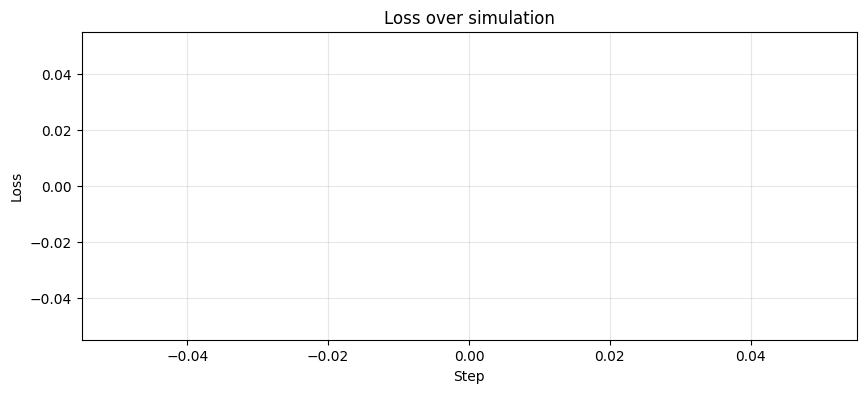

In [ ]:
import sys
from threading import Event, Thread

import ipywidgets as widgets
from IPython.display import display

stop_event = Event()
stop_button = widgets.Button(description="Stop simulation", button_style="danger")
stop_status = widgets.HTML(value="<b>Simulation running...</b>")


def on_stop_clicked(_button):
    stop_event.set()
    stop_button.disabled = True
    stop_status.value = "<b>Stop requested. Finishing the current step...</b>"


stop_button.on_click(on_stop_clicked)
display(widgets.HBox([stop_button]), stop_status)


def run_simulation():
    y_true = next(sequ_generator)

    for step, new_value in enumerate(sequ_generator):
        if stop_event.is_set():
            print(f"stopped at step={step}")
            break

        x = y_true
        y_true = new_value

        x_grid, y_grid, y_pred_grid = predict_grid(
            model=srn_subject,
            x=x,
            y_true=y_true,
            unique_vals=unique_vals,
        )

        loss = srn_subject.backprop(y_pred_grid, y_grid)

        y_true_label = unique_vals[y_true]  # get the expected letter
        y_pred = torch.argmax(y_pred_grid).item()
        y_pred_label = unique_vals[y_pred]  # get the predicted letter
        x_label = unique_vals[x]  # get the input letter

        is_correct = y_true_label == y_pred_label
        loss_value = float(loss.item() if hasattr(loss, "item") else loss)
        loss_evolution.append(loss_value)

        print(
            f"step={step}, x={x_label}, y={y_true_label}, y_pred={y_pred_label}, correct={is_correct}, loss={loss_value}",
            end="\r",
        )

        if y_true_label in ["d", "e", "f"]:
            true_predictable.append(is_correct)

    stop_status.value = "<b>Simulation finished.</b>" if not stop_event.is_set() else stop_status.value


simulation_thread = Thread(target=run_simulation, daemon=True)
simulation_thread.start()

def plot_loss_when_done():
    simulation_thread.join()
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(loss_evolution, color="tab:blue", linewidth=1.5)
    ax.set_title("Loss over simulation")
    ax.set_xlabel("Step")
    ax.set_ylabel("Loss")
    ax.grid(True, alpha=0.3)
    plt.show()

plot_thread = Thread(target=plot_loss_when_done, daemon=True)
plot_thread.start()


Visibly, with enough simulation steps, the srn can predict a predictable value without error.
For a->d, b->e, c->f and 24 embeddings, the number of possible 3 tuples is:
$$\text{3 steps possibilities} = 3 * 24 = 72 $$
So there is a chance that the srn simply overfit on all the possiblities if there is too much steps.